In [1]:
from GenPaths import * # this provides PROPATH which can help load stuff (and the paths to find the PDEhelpers stuff)

from lmfit import Model, Parameters
import lmfit as lm

from scipy import optimize as opt

# if you want this to be easier
#export PYTHONPATH="${PYTHONPATH}:/full/path/to/helpers"

import numpy as np
import matplotlib.pyplot as plt

# from PDEhelpers import * # this causes errors because of class naming same as module naming
from PDEhelpers.PhotonInfo import *
from PDEhelpers.OpticsDataLoader import *

from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit

from PDEhelpers import PDEStyle as MS
# MS.ShowMyStyles()
ms = MS.MyStyleSet()
ms.SetMPLcolors()

In [2]:
x1, r1, x2, r2 = np.genfromtxt(PROPATH+"literatureData/vuv_Ref_air_nexo.csv", skip_header= 1, delimiter=",", unpack=True)
mask = (x1 > 125)
x1 = x1[mask]
r1 = r1[mask]
mask = (x2 > 125)
x2 = x2[mask]
r2 = r2[mask]
if(np.mean(r1) > 1 or np.mean(r2) > 1):
    r1 = r1/100
    r2 = r2/100

In [4]:
def func_Ref(wlen, theta1 = 0, toxide=16.5, FF=0.7, scaleDown=0.3, gausSigma = 0):
    photon = PhotonInfo(wlen, theta_1=theta1, dataHelper=None)
    totalRef = FF * (1-scaleDown) * photon.Wave_TotalReflection(toxide)
    
    print(theta1, toxide, FF, scaleDown)
    return totalRef

refData = np.array(([x1, r1], [x2, r2]))
# Parameters = lm.Parameters()

def allRef_Residuals(toxide, scaleDown1, scaleDown2, dictArgs):
    residuals = []
    refData = dictArgs["refData"]
    thetaList = dictArgs["thetaList"]
    ffList = dictArgs["ffList"]
    
    for i, oneD in enumerate(refData):
        x, y = oneD[0], oneD[1]
        yFunc = func_Ref(wlen=x, theta1=thetaList[i], toxide=toxide, FF=ffList[i], scaleDown=scaleDown)
        residuals.append(y - yFunc)
    return np.sum(np.concatenate(residuals))

ref_fixed_argsDict = {'refData':refData, 'thetaList':[0, 0], 'ffList':[0.6, 0.7]}

allRef_Residuals(toxide=15, scaleDown=0.3, dictArgs=ref_fixed_argsDict)

opt.minimize(allRef_Residuals, x0=[15, 0.3], args=(ref_fixed_argsDict), method='Nelder-Mead')

TypeError: allRef_Residuals() got an unexpected keyword argument 'scaleDown'

In [13]:
def lineTest(x, m, b, sigmaWidth=None):
    
    y = m*x**2 + b
    
    if sigmaWidth is not None:
        y = myfunc_gaussian(xCenter=x, func=lineTest, range=4*sigmaWidth, sigma=sigmaWidth)
        
    return y

def myfunc_gaussian(xCenter, func, range, sigma, *args):
    
    xVals = np.linspace(xCenter-range, xCenter+range, 50, endpoint=True)
    yVals = func(xVals, *args)
    yGauss = scipy.stats.norm.pdf(xVals, loc=xCenter, scale=sigma)
    return y *10

lineTest(4, 1, 1, sigmaWidth=None)
lineTest(4, 1, 1, sigmaWidth=1)

2

       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.017542638865195047
             x: [ 1.742e+01  2.737e-01  2.375e-01]
           nit: 56
          nfev: 105
 final_simplex: (array([[ 1.742e+01,  2.737e-01,  2.375e-01],
                       [ 1.742e+01,  2.737e-01,  2.375e-01],
                       [ 1.742e+01,  2.737e-01,  2.375e-01],
                       [ 1.742e+01,  2.737e-01,  2.375e-01]]), array([ 1.754e-02,  1.754e-02,  1.754e-02,  1.754e-02]))


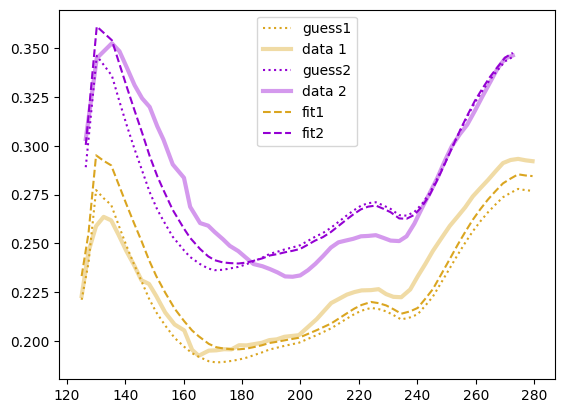

In [30]:
def func_Ref(wlen, theta1 = 0, toxide=16.5, FF=0.7, scaleDown=0.3, gausSigma = None):
    photon = PhotonInfo(wlen, theta_1=theta1, dataHelper=None)
    totalRef = FF * (1-scaleDown) * photon.Wave_TotalReflection(toxide)
    # print(theta1, toxide, FF, scaleDown)
    
    if gausSigma is not None and gausSigma > 0: # expensive but simple/works/robust
        stepPerSigma = 4
        stepSize = gausSigma / stepPerSigma
        newXVals = np.arange(min(wlen), max(wlen) + stepSize, stepSize)
        smoothedRefVals = func_Ref(newXVals, theta1=theta1, toxide=toxide, FF=FF, scaleDown=scaleDown, gausSigma=None)
        smoothedRefVals = gaussian_filter1d(smoothedRefVals, sigma=gausSigma)
        refInt = interp1d(newXVals, smoothedRefVals, kind='linear', fill_value=0)
        return refInt(wlen)
    
    return totalRef    

refData = np.array(([x1, r1], [x2, r2]))


refPars = Parameters()
refPars.add("toxide", value=16.5, min=1, max=250)
for i, oneD in enumerate(refData):
    refPars.add("sd_"+str(i), value=0.3, min=0, max=1) # scaleDown for each x,y in refData
# refPars.add("sd_1", value=0.1, min=0, max=1)
# refPars.add("sd_2", value=0.1, min=0, max=1)


# fixed Pars global

# float Pars global

# per run Fixed

# per run float

floatPars = {"toxide0": 16.5, "scaleDown1": 0.3, "scaleDown2": 0.25}
fixedPars = {"FF": [0.6, 0.7], "theta1": 0, "gausSigma": None} # these can be array when list
# print(floatPars)

def hardRes(data, floatParams, fixedParams):
    # fullIn = {**floatParams, **fixedParams}
    
    print(data.shape)
    print(len(data))
    reses = []
    for i, oneD in enumerate(data):
        x = oneD[0]
        y = oneD[1]
        
        # global - floating
        toxd = floatParams["toxide0"]
        
        
        # individual/per dataset - floating
        floatsd = floatParams["scaleDown"+str(i+1)]
        print(floatsd)
        print(type(floatsd))
        
        ## individual - fixed
        if len(fixedParams["FF"]) > 1:
            print("FF is an array")
            indiv_FF = fixedParams["FF"][i]
            print(indiv_FF)
            print(type(indiv_FF))
        elif "FF" in fixedParams: # global - fixed
            print("FF is a single value")
            indiv_FF = fixedParams["FF"]
            
        
        # new dictionary for each data set        
        dataSetFloat = {"toxide": toxd, "scaleDown": floatsd}
        dataSetFixed = {"FF": indiv_FF, "theta1": fixedParams["theta1"], "gausSigma": fixedParams["gausSigma"]}
        
        yFunc = func_Ref(wlen=x, **dataSetFloat, **dataSetFixed)
        # yErr = oneD[2]
        oneDRes = (y - yFunc)**2
    
        plt.plot(x, yFunc, ms.GetNextColor(), linestyle = "--")
        plt.plot(x, y, ms.GetNextColor(1))
        
    return oneDRes

# x0 is toxide, sd1, sd2
def explicitRes(x0, data, FFlist, thetaList, gausSigma):
    reses = []
    for i, oneD in enumerate(data):
        x = oneD[0]
        y = oneD[1]
        
        yFunc = func_Ref(wlen=x, toxide=x0[0], scaleDown=x0[i+1], theta1=thetaList[i], FF=FFlist[i], gausSigma=gausSigma)
        
        # yErr = oneD[2]
        oneDRes = (y - yFunc)**2
        reses.append(oneDRes)
        
    return np.sum(reses)

def explicitWrapper(x0, otherDict):
    return explicitRes(x0, **otherDict)

def plotData_andGuess(x0, refData, FFlist, thetaList, gausSigma, ax=None, fitOpt = False):
    ax = ax if ax is not None else plt.gca()
    for i, oneD in enumerate(refData):
        col = ms.allColsStr[i]
        x = oneD[0]
        y = oneD[1]
        yFunc = func_Ref(wlen=x, toxide=x0[0], scaleDown=x0[i+1], theta1=thetaList[i], FF=FFlist[i], gausSigma=gausSigma)
        if fitOpt is False:
            ax.plot(x, yFunc, col, linestyle = ":", label = "guess"+str(i+1))
            ax.plot(x, y, col, linewidth = 3, alpha = 0.4, label = "data "+str(i+1))
        else:
            ax.plot(x, yFunc, col, linestyle = "--", label = "fit"+str(i+1))        
    return


# def resWrapper(x0, float_dict, fixed_dict):
    
#     # Convert the list of parameters to a dictionary
#     params = {key: val for key, val in zip(opt_keys, x)}
#     # Add the fixed parameters
#     params.update(fixed_params)
#     return hardRes(params)

# d_data = {"data": refData}
# hardRes(refData, floatPars, fixedPars)

ffList = [0.6, 0.7]
thetaList = [6.8, 6.8]
gausSigma = None

explicit_x0 = [16.5, 0.3, 0.25]
explicit_Other = {"data": refData, "FFlist": ffList, "thetaList": thetaList, "gausSigma": gausSigma}

plotData_andGuess(explicit_x0, refData, ffList, thetaList, gausSigma)

explicitRes(explicit_x0, refData, ffList, thetaList, gausSigma)
explicitRes(explicit_x0, **explicit_Other)
# # resLM = lm.minimize(hardRes, refPars, args=(func_Ref, d1Fixed, d_data)

res = opt.minimize(fun=explicitWrapper, x0=explicit_x0, args=explicit_Other, method='Nelder-Mead')

plotData_andGuess(res.x, refData, ffList, thetaList, gausSigma, fitOpt=True)

plt.legend()

print(res)

In [ ]:

# def buildParSet(data, sharedPars_names, indivPars_names, fixedPars_names):
#     parSet = Parameters()
#     for name in sharedPars_names:
#         parSet.add(name, value=data[name], vary=False)
#     for name in indivPar_names:
#         parSet.add(name, value=data[name], vary=True)
#     for name in fixedNames:
#         parSet.add(name, value=data[name], vary=False)
#     return parSet

In [6]:
dAngles = {"d1":6.8, "d2":17, "d3":37.2} # only have data d1 here
FF1 = 0.6
FF2 = 0.7

# vertical scaling

# repeat with lmfit


## define names for everything to avoid typing it all out
ntoxide = "toxide"
ntheta1 = "theta1"
nFF = "FF"
nscaleDown = "scaleDown"

# prefix names
np1 = "d1_"
np2 = "d2_"
#! add check that names are consistent with function

### building Model ###
model1 = Model(func_Ref, prefix=np1, independent_vars=["wlen", "theta1"])
model2 = Model(func_Ref, prefix=np2, independent_vars=["wlen", "theta1"])
composite_model = model1 + model2

a = composite_model.eval(wlen=160, theta1=6.8, d1_toxide=16.5, d1_FF=0.6, d1_scaleDown=0.3, d2_toxide=16.5, d2_FF=0.7, d2_scaleDown=0.3)
print(a)

parRef = Parameters()

# fixed parameters
parRef.add(np1+nFF, value=FF1, vary=False)
parRef.add(np2+nFF, value=FF2, vary=False)

# individual floating parameters
parRef.add(np1+nscaleDown, value=0.25, min=0.01, max=0.5, brute_step=0.01, vary=False)
parRef.add(np2+nscaleDown, value=0.3, min=0.01, max=0.5, brute_step=0.01, vary=False)

# shared parameters
parRef.add(np1+ntoxide, value=12, min=1, max=50, brute_step=0.1, vary=True)
# parRef.add(np2+ntoxide, expr = np1+ntoxide)
parRef.add(np2+ntoxide, value=16.5, min=0.1, max=500, brute_step=0.1, vary=True)

## adding all data together
fit_rData = np.concatenate((r1, r2))
fit_wlenData = np.concatenate((x1, x2))
# fit_theta1 = np.concatenate((np.full(x1.shape, dAngles["d1"]), np.full(x2.shape, dAngles["d1"]))) # need a theta datapoint for each x point. this is why gridmesh flatten can be used
fit_theta1 = dAngles["d1"]
# print(fit_theta1)

result = composite_model.fit(data=fit_rData, params=parRef, wlen=fit_wlenData, theta1=fit_theta1, method='bfgs')
print(result.fit_report())

######## Plotting ########
plot1, = plt.plot(x1, r1, linewidth = 4, linestyle = "--", alpha = 0.4, color = ms.GetNextColor(1), label="vuv4 - 50um pitch")

# print(dAngles["d1"])
yr1_guess1 = func_Ref(x1, theta1 = dAngles["d1"], toxide=20, FF=FF1, scaleDown=0.3)
# yr1_guess2 = func_Ref(x1, theta1 = dAngles["d1"], toxide=20, FF=FF1, scaleDown=0.3)
plt.plot(x1, yr1_guess1, color = ms.GetNextColor(1), linestyle = ":", label="guess, 20 nm")
# plt.plot(x1, yr1_guess2, color = ms.GetNextColor(1), linestyle = "-.", label="guess, 12 nm")

plot2, = plt.plot(x2, r2, linewidth = 4, linestyle = "--", color = ms.GetNextColor(), alpha = 0.4, label="vuv4 - 75um pitch")
yr2_guess1 = func_Ref(x2, theta1 = dAngles["d1"], toxide = 20, FF=FF2, scaleDown=0.25)
plt.plot(x2, yr2_guess1, color = ms.GetNextColor(1), linestyle = ":", label="guess, 20 nm")        

## fit results
plt.plot(x1, func_Ref(x1, theta1 = dAngles["d1"], toxide=result.params[np1+ntoxide].value, FF=FF1, scaleDown=result.params[np1+nscaleDown].value), color = plot1.get_color(), label=f"fit, {result.params[np1+ntoxide].value:0.2f} nm")
plt.plot(x2, func_Ref(x2, theta1 = dAngles["d1"], toxide=result.params[np2+ntoxide].value, FF=FF2, scaleDown=result.params[np2+nscaleDown].value), color = plot2.get_color(), label=f"fit, {result.params[np2+ntoxide].value:0.2f} nm")

plt.title("FF (All ref) scaled by 0.7")
plt.legend()

plt.legend()

0.4275935962667511


ValueError: Assign each parameter an initial value by passing Parameters or keyword arguments to fit.
Missing parameters: ['d1_gausSigma', 'd2_gausSigma']
Non initialized parameters: []

In [ ]:
print("wut")

wut
